In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("imported")

imported


In [3]:
from google.colab import files
uploaded = files.upload()

Saving machine_rul_dataset.csv to machine_rul_dataset.csv


In [4]:
df=pd.read_csv("machine_rul_dataset.csv")
print(df)

    Record_ID Machine_Type Operating_Mode Lubrication_Type  Temperature_C  \
0    REC_1000       Type_C            Eco          Mineral          85.80   
1    REC_1001       Type_A       Standard          Mineral          78.69   
2    REC_1002       Type_C            Eco          Mineral          84.75   
3    REC_1003       Type_C       Standard          Mineral          82.56   
4    REC_1004       Type_A       Standard        Synthetic          65.05   
..        ...          ...            ...              ...            ...   
195  REC_1195       Type_B       Standard        Synthetic          92.76   
196  REC_1196       Type_C       Standard          Mineral          75.93   
197  REC_1197       Type_C      High_Load          Mineral          64.66   
198  REC_1198       Type_B      High_Load        Synthetic          93.28   
199  REC_1199       Type_A      High_Load          Mineral          81.47   

     Vibration_mm_s  Pressure_kPa     RPM  Operating_Hours  \
0            

In [5]:
df.head()

,Record_ID,Machine_Type,Operating_Mode,Lubrication_Type,Temperature_C,Vibration_mm_s,Pressure_kPa,RPM,Operating_Hours,Remaining_Useful_Life_Hours
0,REC_1000,Type_C,Eco,Mineral,85.80,1.348,91.40,3081.2,2282.0,3137.38
1,REC_1001,Type_A,Standard,Mineral,78.69,0.705,91.80,2393.7,2622.6,3224.85
2,REC_1002,Type_C,Eco,Mineral,84.75,1.001,99.51,3619.0,1860.2,3496.60
3,REC_1003,Type_C,Standard,Mineral,82.56,1.177,91.85,3718.4,3005.5,2975.30
4,REC_1004,Type_A,Standard,Synthetic,65.05,2.057,89.31,2754.9,901.3,3931.38


In [6]:
df.describe()

,Temperature_C,Vibration_mm_s,Pressure_kPa,RPM,Operating_Hours,Remaining_Useful_Life_Hours
count,195.000000,200.000000,195.000000,200.00000,200.000000,200.000000
mean,75.784051,1.989745,100.233487,3073.21700,2550.060000,2994.279400
std,11.540289,1.477692,14.466782,383.10934,1392.304033,799.730762
min,49.510000,0.507000,60.240000,2030.40000,124.200000,815.620000
25%,67.525000,0.921250,90.640000,2802.95000,1347.575000,2351.507500
50%,75.290000,1.540500,99.510000,3080.20000,2604.050000,2995.745000
75%,83.255000,2.549250,109.805000,3306.72500,3611.525000,3583.535000
max,111.950000,9.152000,139.490000,4010.80000,4997.100000,4939.970000


In [7]:
df.columns

Index(['Record_ID', 'Machine_Type', 'Operating_Mode', 'Lubrication_Type',
       'Temperature_C', 'Vibration_mm_s', 'Pressure_kPa', 'RPM',
       'Operating_Hours', 'Remaining_Useful_Life_Hours'],
      dtype='object')

In [8]:
df.shape

(200, 10)

In [9]:
df.dtypes

,0
Record_ID,object
Machine_Type,object
Operating_Mode,object
Lubrication_Type,object
Temperature_C,float64
Vibration_mm_s,float64
Pressure_kPa,float64
RPM,float64
Operating_Hours,float64
Remaining_Useful_Life_Hours,float64


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.isnull().sum()

,0
Record_ID,0
Machine_Type,5
Operating_Mode,0
Lubrication_Type,0
Temperature_C,5
Vibration_mm_s,0
Pressure_kPa,5
RPM,0
Operating_Hours,0
Remaining_Useful_Life_Hours,0


In [12]:
print(df.skew(numeric_only=True))

Temperature_C                  0.175118
Vibration_mm_s                 1.786524
Pressure_kPa                   0.140560
RPM                           -0.092135
Operating_Hours               -0.028711
Remaining_Useful_Life_Hours   -0.037268
dtype: float64


In [13]:
print(df.corr(numeric_only=True))

                             Temperature_C  Vibration_mm_s  Pressure_kPa  \
Temperature_C                     1.000000       -0.066762      0.010317   
Vibration_mm_s                   -0.066762        1.000000      0.072213   
Pressure_kPa                      0.010317        0.072213      1.000000   
RPM                               0.009986       -0.046991      0.157383   
Operating_Hours                  -0.028523       -0.000209     -0.019850   
Remaining_Useful_Life_Hours      -0.159847       -0.445378     -0.010244   

                                  RPM  Operating_Hours  \
Temperature_C                0.009986        -0.028523   
Vibration_mm_s              -0.046991        -0.000209   
Pressure_kPa                 0.157383        -0.019850   
RPM                          1.000000         0.014663   
Operating_Hours              0.014663         1.000000   
Remaining_Useful_Life_Hours  0.006721        -0.865251   

                             Remaining_Useful_Life_Hours  
T

In [14]:
df=df.drop(columns=["Record_ID"])

In [15]:
df.isnull().sum()

,0
Machine_Type,5
Operating_Mode,0
Lubrication_Type,0
Temperature_C,5
Vibration_mm_s,0
Pressure_kPa,5
RPM,0
Operating_Hours,0
Remaining_Useful_Life_Hours,0


In [16]:
X=df.drop(columns=["Remaining_Useful_Life_Hours"])
y=df["Remaining_Useful_Life_Hours"]
print(X)
print(y)

    Machine_Type Operating_Mode Lubrication_Type  Temperature_C  \
0         Type_C            Eco          Mineral          85.80   
1         Type_A       Standard          Mineral          78.69   
2         Type_C            Eco          Mineral          84.75   
3         Type_C       Standard          Mineral          82.56   
4         Type_A       Standard        Synthetic          65.05   
..           ...            ...              ...            ...   
195       Type_B       Standard        Synthetic          92.76   
196       Type_C       Standard          Mineral          75.93   
197       Type_C      High_Load          Mineral          64.66   
198       Type_B      High_Load        Synthetic          93.28   
199       Type_A      High_Load          Mineral          81.47   

     Vibration_mm_s  Pressure_kPa     RPM  Operating_Hours  
0             1.348         91.40  3081.2           2282.0  
1             0.705         91.80  2393.7           2622.6  
2           

In [17]:
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

print(num_cols)
print(cat_cols)

['Temperature_C', 'Vibration_mm_s', 'Pressure_kPa', 'RPM', 'Operating_Hours']
['Machine_Type', 'Operating_Mode', 'Lubrication_Type']


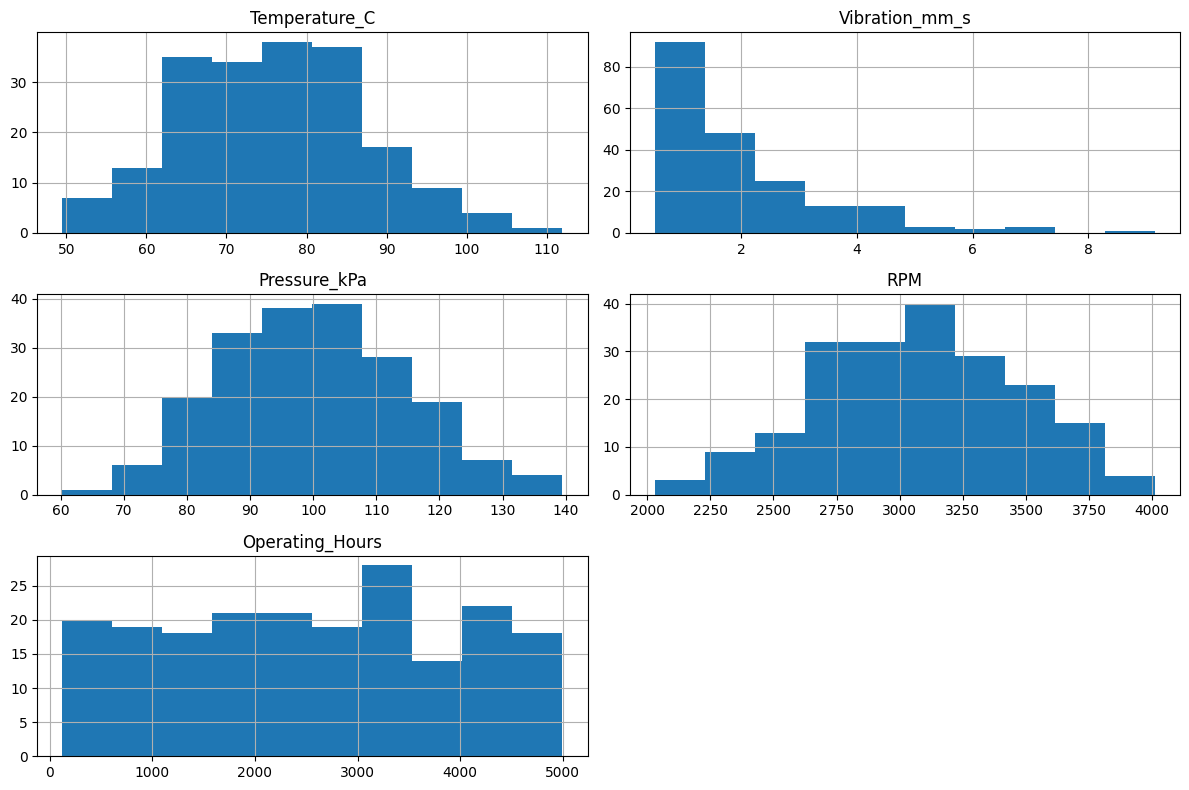

In [18]:
X[num_cols].hist(figsize=(12,8))
plt.tight_layout()
plt.show()

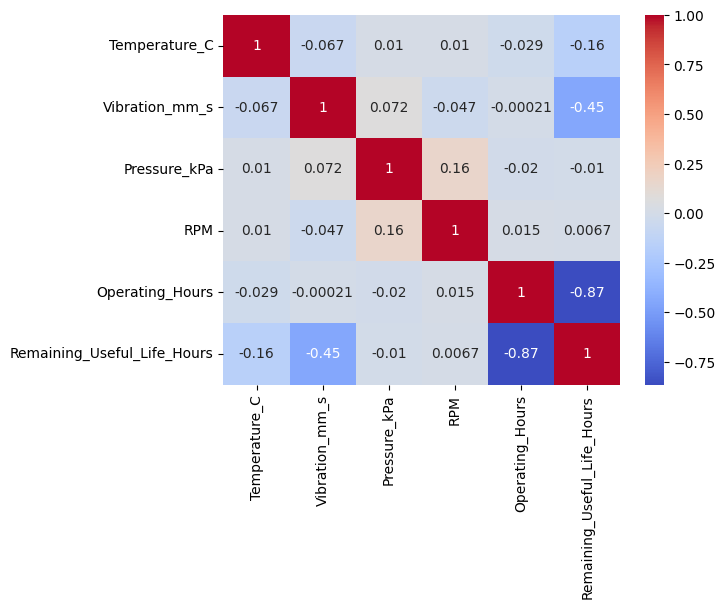

In [21]:
sns.heatmap(
    df.corr(numeric_only=True),
            annot=True,
            cmap="coolwarm"
)
plt.show()


In [22]:
for cols in num_cols:
  Q1=df[cols].quantile(0.25)
  Q3=df[cols].quantile(0.75)
  IQR=Q3-Q1
  lower_bound=Q1 -1.5*IQR
  upper_bound=Q3+1.5*IQR

  print(cols,"outliers:",
        ((X[cols]<lower_bound)|
         (X[cols]>upper_bound)).sum())


Temperature_C outliers: 1
Vibration_mm_s outliers: 8
Pressure_kPa outliers: 2
RPM outliers: 1
Operating_Hours outliers: 0


In [34]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

for num in num_cols:
  df[num]=df[num].fillna(df[num].median())



In [35]:
df.isnull().sum()

,0
Machine_Type,5
Operating_Mode,0
Lubrication_Type,0
Temperature_C,0
Vibration_mm_s,0
Pressure_kPa,0
RPM,0
Operating_Hours,0
Remaining_Useful_Life_Hours,0


In [36]:
for cat in cat_cols:
  df[cat]=df[cat].fillna(df[cat].mode()[0])

In [37]:
df.isnull().sum()

,0
Machine_Type,0
Operating_Mode,0
Lubrication_Type,0
Temperature_C,0
Vibration_mm_s,0
Pressure_kPa,0
RPM,0
Operating_Hours,0
Remaining_Useful_Life_Hours,0


In [38]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
                        X, y, test_size=0.2, random_state=42)



In [39]:
print(X_train.shape)

(160, 8)


In [44]:
num_pipe=Pipeline([("imputer",SimpleImputer(strategy="median")),
                   ("scaler",StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
("encoder", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", num_pipe, num_cols),
("cat", cat_pipe, cat_cols)])

In [45]:
X_train_encoded=preprocessor.fit_transform(X_train)
X_test_encoded=preprocessor.transform(X_test)

In [47]:
print(X_train_encoded.shape)

(160, 13)


In [49]:
print(np.isnan(X_train_encoded.sum()))

False


In [50]:
from sklearn.svm import SVC, SVR
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (r2_score, mean_squared_error,mean_absolute_error,mean_absolute_percentage_error)

svr=SVR(kernel='rbf')

param_grid={
    'C':[0.1,0.7,0.8],
    'gamma':['scale','auto'],
    'epsilon':[0.1,0.9,1.0]
}

grid=GridSearchCV(
    estimator=svr,
    param_grid=param_grid,
    cv=5,
    scoring='r2'
)

grid.fit(X_train_encoded,y_train)

best_model1=grid.best_estimator_
best_score1=grid.best_score_
best_param1=grid.best_params_

y_pred_svr=best_model1.predict(X_test_encoded)





In [51]:
print(best_model1)

SVR(C=0.8, epsilon=1.0, gamma='auto')


In [52]:
print(best_score1)

0.0031121081169812824


In [53]:
print(best_param1)

{'C': 0.8, 'epsilon': 1.0, 'gamma': 'auto'}


In [54]:
print(r2_score(y_test,y_pred_svr))

-0.005043222818046589


In [56]:
print(mean_squared_error(y_test,y_pred_svr))

650467.3040471394


In [57]:
from sklearn.model_selection import KFold, cross_val_score
score1=-cross_val_score(best_model1,X_train_encoded,y_train,cv=5,scoring='neg_root_mean_squared_error')

In [58]:
print(score1)

[832.56119114 811.75066692 755.19873024 834.52894564 717.53627396]


In [60]:
from sklearn.decomposition import PCA
pca=PCA()
pca.fit(X_train_encoded)


cum_var=np.cumsum(pca.explained_variance_ratio_)
n_components_95=int(np.argmax(cum_var>=0.95)+1)




In [61]:
cum_var=np.cumsum(pca.explained_variance_ratio_)

In [62]:
n_components_95=int(np.argmax(cum_var>=0.95)+1)

In [63]:
print(X_train_encoded.shape)

(160, 13)


In [64]:
print(n_components_95)

9


In [65]:
print(cum_var)

[0.16928328 0.33216192 0.48064519 0.62262675 0.74869972 0.82169331
 0.87617592 0.92486276 0.96549635 1.         1.         1.
 1.        ]


In [67]:
pca_full=PCA(n_components=n_components_95,random_state=42,svd_solver='arpack')
X_train_pca=pca_full.fit_transform(X_train_encoded)
X_test_pca=pca_full.transform(X_test_encoded)

print(X_train_pca.shape)

(160, 9)


In [69]:
svr_pca=SVR(kernel='rbf')
param_grid={
    'C':[0.1,0.7,0.8],
    'gamma':['scale','auto'],
    'epsilon':[0.1,0.9,1.0]
}

grid_pca=GridSearchCV(
    estimator=svr_pca,
    param_grid=param_grid,
    cv=5,
    scoring='r2'
)

grid_pca.fit(X_train_pca,y_train)

best_model2=grid_pca.best_estimator_
best_score2=grid_pca.best_score_
best_param2=grid_pca.best_params_

y_pred_svr_pca=best_model2.predict(X_test_pca)

In [70]:
print(best_model2)

SVR(C=0.8, epsilon=1.0, gamma='auto')


In [71]:
print(best_score2)

0.003280960209822048


In [72]:
print(best_param2)

{'C': 0.8, 'epsilon': 1.0, 'gamma': 'auto'}


In [73]:
scores2=-cross_val_score(best_model2,X_train_pca,y_train,cv=5,scoring='neg_root_mean_squared_error')

In [74]:
print(scores2)

[832.56280934 811.73880194 754.98777536 834.50719596 717.46080888]


In [77]:
table=pd.DataFrame({
    "Fold":[1,2,3,4,5],
    "RMSE Without PCA":score1,
    "RMSE With pca":scores2,
    "Difference":scores2-score1
})

print(table)

   Fold  RMSE Without PCA  RMSE With pca  Difference
0     1        832.561191     832.562809    0.001618
1     2        811.750667     811.738802   -0.011865
2     3        755.198730     754.987775   -0.210955
3     4        834.528946     834.507196   -0.021750
4     5        717.536274     717.460809   -0.075465


In [78]:
from scipy.stats import ttest_rel, ttest_ind, wilcoxon

paired_stat, paired_p = ttest_rel(score1, scores2)


if paired_p < 0.05:
  print("Paired t-test: Significant difference")
else:
  print("Paired t-test: No significant difference")

Paired t-test: No significant difference


In [79]:
model_scores=[score1,scores2]
model_means = [np.mean(scores) for scores in model_scores]
best_index = np.argmax(model_means)
print(f"Best model: Model {best_index + 1} with mean score = {model_means[best_index]:.4f}")

Best model: Model 1 with mean score = 790.3152
